<a href="https://colab.research.google.com/github/240447-stack/AI-ML/blob/main/regression_and_UI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Install required libraries
!pip install -q gradio

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import gradio as gr

In [ ]:
# Download Wine Quality dataset

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

df = pd.read_csv(url, sep=";")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [ ]:
# Display dataset information

print("Dataset Information:")
print()

df.info()

Dataset Information:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [ ]:
# Check for missing values

print("Missing Values:")
print(df.isnull().sum())


Missing Values:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64


In [ ]:
# Statistical summary

df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


Quality Distribution:
quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64


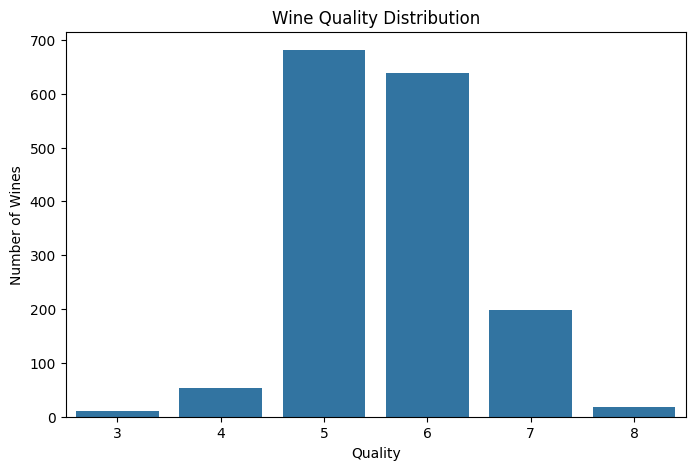

In [ ]:
# Display distribution of original quality scores

print("Quality Distribution:")
print(df["quality"].value_counts().sort_index())

plt.figure(figsize=(8, 5))

sns.countplot(
    x="quality",
    data=df
)

plt.title("Wine Quality Distribution")
plt.xlabel("Quality")
plt.ylabel("Number of Wines")

plt.show()

In [ ]:
# Convert wine quality into binary classification

df["good_quality"] = (df["quality"] >= 6).astype(int)

print(df[["quality", "good_quality"]].head(20))

print("Binary Class Distribution:")
print(df["good_quality"].value_counts())

print("\nClass Meaning:")
print("0 = Poor Quality")
print("1 = Good Quality")

    quality  good_quality
0         5             0
1         5             0
2         5             0
3         6             1
4         5             0
5         5             0
6         5             0
7         7             1
8         7             1
9         5             0
10        5             0
11        5             0
12        5             0
13        5             0
14        5             0
15        5             0
16        7             1
17        5             0
18        4             0
19        6             1
Binary Class Distribution:
good_quality
1    855
0    744
Name: count, dtype: int64

Class Meaning:
0 = Poor Quality
1 = Good Quality


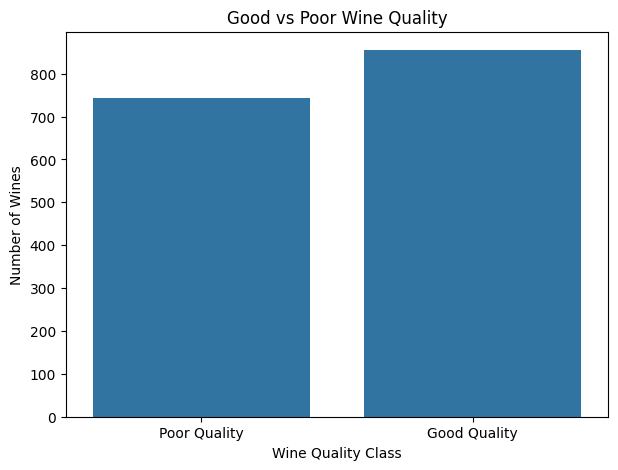

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    x="good_quality",
    data=df
)

plt.title("Good vs Poor Wine Quality")

plt.xlabel("Wine Quality Class")
plt.ylabel("Number of Wines")

plt.xticks(
    [0, 1],
    ["Poor Quality", "Good Quality"]
)

plt.show()

In [ ]:
# Features

X = df.drop(
    columns=["quality", "good_quality"]
)

# Target

y = df["good_quality"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("good_quality")

Features:
['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar', 'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density', 'pH', 'sulphates', 'alcohol']

Target:
good_quality


In [ ]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1279
Testing samples: 320


In [ ]:
# Feature scaling

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")

Feature scaling completed.


In [ ]:
# Create Logistic Regression model

model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model

model.fit(
    X_train_scaled,
    y_train
)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


In [ ]:
# Predict test data

y_pred = model.predict(X_test_scaled)

# Prediction probabilities

y_probability = model.predict_proba(X_test_scaled)[:, 1]

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred[:10])

print("\nFirst 10 probabilities:")
print(y_probability[:10])

Predictions generated successfully!

First 10 predictions:
[0 1 0 0 1 1 0 0 0 1]

First 10 probabilities:
[0.33370864 0.51317799 0.08557078 0.28567419 0.86571498 0.96834124
 0.14182648 0.09345558 0.14198749 0.87223411]


In [ ]:
# Calculate evaluation metrics

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred)

recall = recall_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred)


print("Model Evaluation")
print("--------------------------")

print(f"Accuracy  : {accuracy * 100:.2f}%")

print(f"Precision : {precision * 100:.2f}%")

print(f"Recall    : {recall * 100:.2f}%")

print(f"F1 Score  : {f1 * 100:.2f}%")

Model Evaluation
--------------------------
Accuracy  : 74.06%
Precision : 76.83%
Recall    : 73.68%
F1 Score  : 75.22%


In [ ]:
print("Classification Report")
print("======================")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "Poor Quality",
            "Good Quality"
        ]
    )
)

Classification Report
              precision    recall  f1-score   support

Poor Quality       0.71      0.74      0.73       149
Good Quality       0.77      0.74      0.75       171

    accuracy                           0.74       320
   macro avg       0.74      0.74      0.74       320
weighted avg       0.74      0.74      0.74       320



In [ ]:
# Create confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[111  38]
 [ 45 126]]


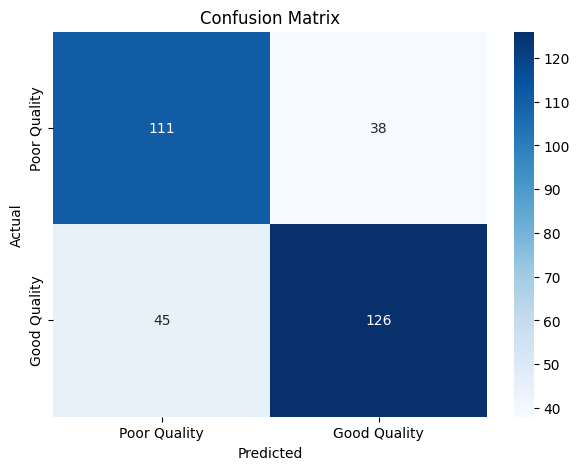

In [ ]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Poor Quality",
        "Good Quality"
    ],
    yticklabels=[
        "Poor Quality",
        "Good Quality"
    ]
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

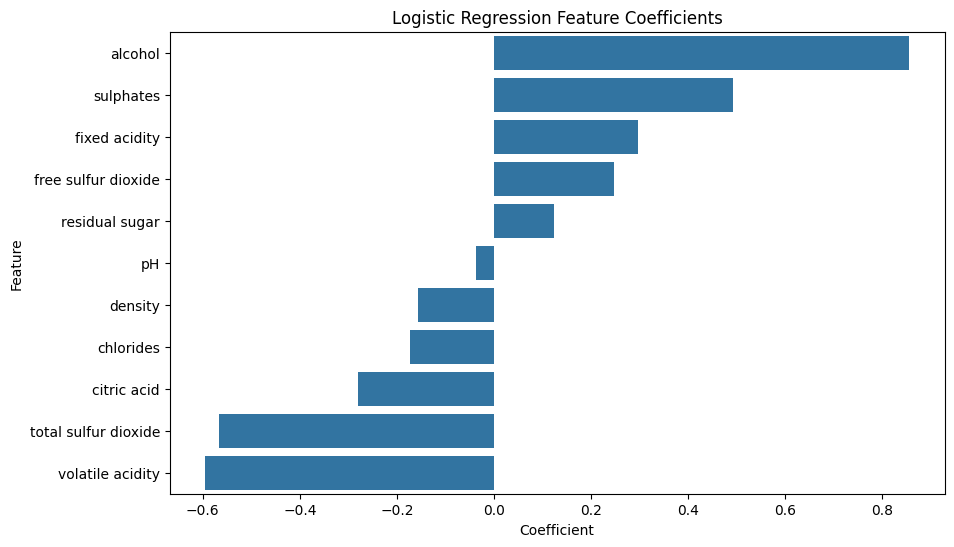

In [ ]:
# Get model coefficients

coefficients = model.coef_[0]

feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": coefficients
})

feature_importance = feature_importance.sort_values(
    by="Coefficient",
    ascending=False
)

feature_importance



plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Coefficient",
    y="Feature"
)

plt.title("Logistic Regression Feature Coefficients")

plt.xlabel("Coefficient")

plt.ylabel("Feature")

plt.show()

In [ ]:
def predict_wine(
    fixed_acidity,
    volatile_acidity,
    citric_acid,
    residual_sugar,
    chlorides,
    free_sulfur_dioxide,
    total_sulfur_dioxide,
    density,
    ph,
    sulphates,
    alcohol
):

    # Create input DataFrame

    input_data = pd.DataFrame([{
        "fixed acidity": fixed_acidity,
        "volatile acidity": volatile_acidity,
        "citric acid": citric_acid,
        "residual sugar": residual_sugar,
        "chlorides": chlorides,
        "free sulfur dioxide": free_sulfur_dioxide,
        "total sulfur dioxide": total_sulfur_dioxide,
        "density": density,
        "pH": ph,
        "sulphates": sulphates,
        "alcohol": alcohol
    }])

    # Scale input

    input_scaled = scaler.transform(input_data)

    # Prediction

    prediction = model.predict(input_scaled)[0]

    # Probability

    probability = model.predict_proba(input_scaled)[0]

    poor_probability = probability[0] * 100

    good_probability = probability[1] * 100


    if prediction == 1:

        result = "🍷 Good Quality Wine"

        description = (
            "The model predicts that this wine "
            "has good quality."
        )

    else:

        result = "⚠️ Poor Quality Wine"

        description = (
            "The model predicts that this wine "
            "has lower quality."
        )


    return (
        result,
        description,
        f"Good Quality Probability: {good_probability:.2f}%",
        f"Poor Quality Probability: {poor_probability:.2f}%"
    )

In [ ]:
def predict_wine(
    fixed_acidity,
    volatile_acidity,
    citric_acid,
    residual_sugar,
    chlorides,
    free_sulfur_dioxide,
    total_sulfur_dioxide,
    density,
    ph,
    sulphates,
    alcohol
):

    # Create input DataFrame

    input_data = pd.DataFrame([{
        "fixed acidity": fixed_acidity,
        "volatile acidity": volatile_acidity,
        "citric acid": citric_acid,
        "residual sugar": residual_sugar,
        "chlorides": chlorides,
        "free sulfur dioxide": free_sulfur_dioxide,
        "total sulfur dioxide": total_sulfur_dioxide,
        "density": density,
        "pH": ph,
        "sulphates": sulphates,
        "alcohol": alcohol
    }])

    # Scale input

    input_scaled = scaler.transform(input_data)

    # Prediction

    prediction = model.predict(input_scaled)[0]

    # Probability

    probability = model.predict_proba(input_scaled)[0]

    poor_probability = probability[0] * 100

    good_probability = probability[1] * 100


    if prediction == 1:

        result = "🍷 Good Quality Wine"

        description = (
            "The model predicts that this wine "
            "has good quality."
        )

    else:

        result = "⚠️ Poor Quality Wine"

        description = (
            "The model predicts that this wine "
            "has lower quality."
        )


    return (
        result,
        description,
        f"Good Quality Probability: {good_probability:.2f}%",
        f"Poor Quality Probability: {poor_probability:.2f}%"
    )

In [ ]:
with gr.Blocks(
    title="Wine Quality Predictor"
) as demo:

    gr.Markdown(
        """
        # 🍷 Wine Quality Predictor

        ### Logistic Regression Classification

        Enter the chemical properties of a red wine
        to predict its quality.
        """
    )


    with gr.Row():

        with gr.Column():

            fixed_acidity = gr.Number(
                label="Fixed Acidity",
                value=7.4
            )

            volatile_acidity = gr.Number(
                label="Volatile Acidity",
                value=0.70
            )

            citric_acid = gr.Number(
                label="Citric Acid",
                value=0.00
            )

            residual_sugar = gr.Number(
                label="Residual Sugar",
                value=1.9
            )

            chlorides = gr.Number(
                label="Chlorides",
                value=0.076
            )

            free_sulfur_dioxide = gr.Number(
                label="Free Sulfur Dioxide",
                value=11
            )


        with gr.Column():

            total_sulfur_dioxide = gr.Number(
                label="Total Sulfur Dioxide",
                value=34
            )

            density = gr.Number(
                label="Density",
                value=0.9978
            )

            ph = gr.Number(
                label="pH",
                value=3.51
            )

            sulphates = gr.Number(
                label="Sulphates",
                value=0.56
            )

            alcohol = gr.Number(
                label="Alcohol",
                value=9.4
            )


    predict_button = gr.Button(
        "🍷 Predict Wine Quality",
        variant="primary"
    )


    gr.Markdown("## Prediction Result")


    prediction_output = gr.Textbox(
        label="Prediction"
    )

    message_output = gr.Textbox(
        label="Message"
    )

    good_probability = gr.Textbox(
        label="Good Quality Probability"
    )

    poor_probability = gr.Textbox(
        label="Poor Quality Probability"
    )


    predict_button.click(

        fn=predict_wine,

        inputs=[

            fixed_acidity,
            volatile_acidity,
            citric_acid,
            residual_sugar,
            chlorides,
            free_sulfur_dioxide,
            total_sulfur_dioxide,
            density,
            ph,
            sulphates,
            alcohol

        ],

        outputs=[

            prediction_output,
            message_output,
            good_probability,
            poor_probability

        ]

    )


demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e3ee92b163157079df.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
